## Подготовка датасета

Загружаем заказы, предварительно очищенные от пользователей с товарами без метаданных.
Через `.sample()` выбираем 10 000 пользователей с `random_state=42` и сохраняем
все их заказы. Затем оставляем заказы товаров с минимум двумя взаимодействиями
и пользователей с минимум двумя оставшимися заказами.
Фильтры применяем по одному разу. Справочник `nm_meta` сохраняем полностью,
чтобы использовать категории и подкатегории в том числе для товаров без заказов в сэмпле.


In [1]:
import pandas as pd
from prepare_dataset import filter_items, filter_users

orders = pd.read_parquet("data/orders.parquet")
nm_meta = pd.read_parquet("data/nm_meta.parquet")

users = orders["user_id"].drop_duplicates().sort_values().sample(n=10_000, random_state=42)
orders = orders.loc[orders["user_id"].isin(users)].copy()
orders = filter_items(orders, min_interactions=2)
orders = filter_users(orders, min_orders=2)


В итоге осталось 9 128 пользователей, 724 070 заказов и 218 832 товаров с заказами. В `nm_meta` сохранены все 11 320 117 товаров.


## EDA

Проверим качество данных, активность пользователей и товаров, а также категории покупок.


In [2]:
for name, data in [("orders", orders), ("nm_meta", nm_meta)]:
    print(name)
    for column, count in data.isna().sum().items():
        print(f"Пропуски в {column}: {count}")

missing_meta = (~orders["nm_id"].isin(nm_meta["nm_id"])).sum()
print(f"Заказов без метаданных: {missing_meta}")


orders
Пропуски в timestamp: 0
Пропуски в user_id: 0
Пропуски в nm_id: 0
nm_meta
Пропуски в nm_id: 0
Пропуски в category_id: 0
Пропуски в subcategory_id: 0
Заказов без метаданных: 0


Пропусков в заказах и метаданных нет. Для каждого товара в заказах есть метаданные.


In [3]:
order_duplicates = orders.duplicated().sum()
meta_duplicates = nm_meta.duplicated().sum()
repeated_item_ids = nm_meta["nm_id"].duplicated().sum()
repeated_pairs = orders.duplicated(["user_id", "nm_id"]).sum()

print(f"Полных дубликатов заказов: {order_duplicates}")
print(f"Полных дубликатов метаданных: {meta_duplicates}")
print(f"Повторяющихся nm_id в метаданных: {repeated_item_ids}")
print(f"Повторных заказов пары пользователь–товар: {repeated_pairs}")


Полных дубликатов заказов: 0
Полных дубликатов метаданных: 0
Повторяющихся nm_id в метаданных: 0
Повторных заказов пары пользователь–товар: 100621


Полных дубликатов нет, `nm_id` в справочнике уникален. Повторные заказы тех же товаров составляют 13.90% строк: это покупки в разное время, их сохраняем.


Посмотрим длину истории пользователей и число разных покупателей у товаров: от них зависит количество данных для kNN и ALS.


Заказов на пользователя: медиана 50, 90-й перцентиль 187
Товаров с одним покупателем: 17.10%
Плотность матрицы по товарам с заказами: 0.0312%


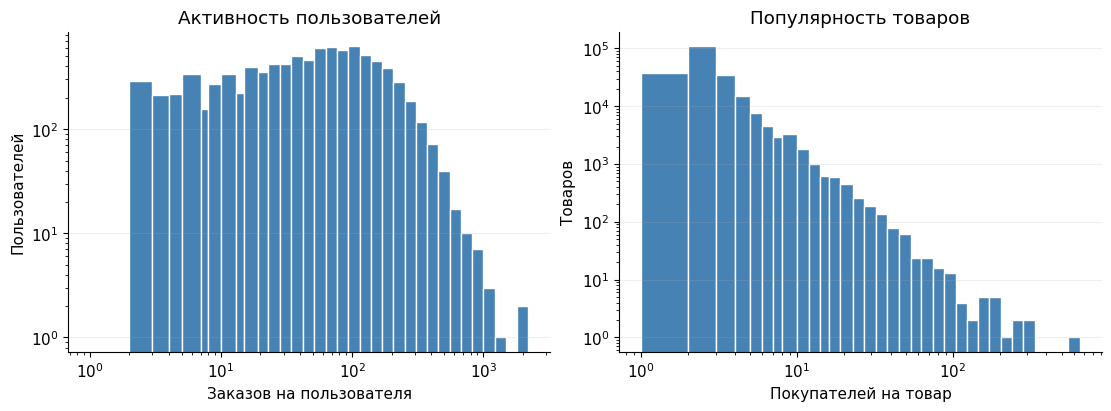

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
user_orders = orders.groupby("user_id").size()
item_users = orders.groupby("nm_id")["user_id"].nunique()
density = item_users.sum() / (len(user_orders) * len(item_users))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, values, title, xlabel, ylabel in [
    (axes[0], user_orders, "Активность пользователей", "Заказов на пользователя", "Пользователей"),
    (axes[1], item_users, "Популярность товаров", "Покупателей на товар", "Товаров"),
]:
    bins = np.unique(np.geomspace(1, values.max() + 1, 40).astype(int))
    ax.hist(values, bins=bins, color="steelblue", edgecolor="white")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel, xscale="log", yscale="log")
    ax.grid(axis="y", alpha=0.2)

print(f"Заказов на пользователя: медиана {user_orders.median():.0f}, 90-й перцентиль {user_orders.quantile(0.9):.0f}")
print(f"Товаров с одним покупателем: {item_users.eq(1).mean():.2%}")
print(f"Плотность матрицы по товарам с заказами: {density:.4%}")
fig.savefig("figures/eda_activity.png", dpi=180)
plt.show()


Медиана истории — 50 заказов; у 10% пользователей — около 187 и более. У 17.1% товаров только один покупатель: фильтр по числу заказов не гарантирует нескольких покупателей у товара. Плотность матрицы по товарам с заказами — 0.0312%, поэтому для коллаборативных моделей нужны разреженные матрицы. Качество далее стоит сравнить отдельно для коротких историй и редких товаров.


Категорий: 92 в каталоге, 83 в заказах
Подкатегорий: 7026 в каталоге, 4119 в заказах
Подкатегорий с несколькими категориями: 0
Доля заказов топ-5 категорий: 52.04%
Категорий на пользователя: медиана 15, 90-й перцентиль 30


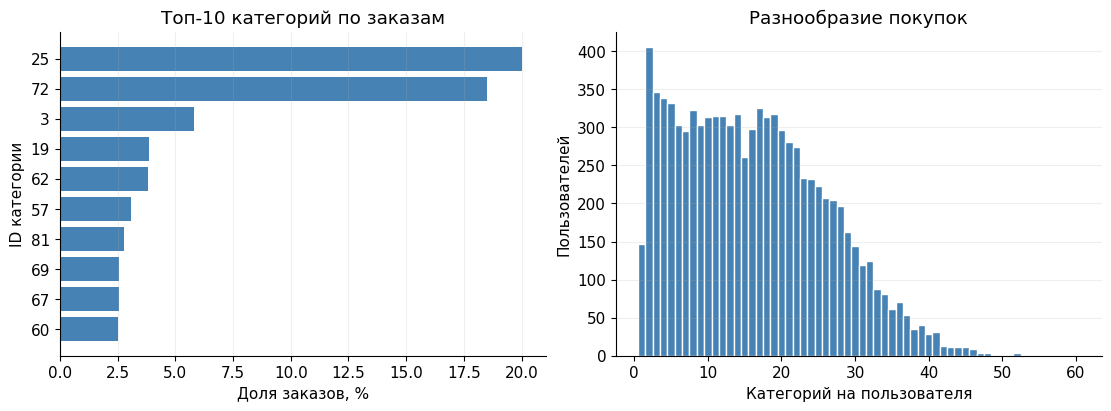

In [5]:
orders_meta = orders.merge(nm_meta, on="nm_id", how="left", validate="many_to_one")
category_share = orders_meta["category_id"].value_counts(normalize=True)
subcategory_share = orders_meta["subcategory_id"].value_counts(normalize=True)
user_categories = orders_meta.groupby("user_id")["category_id"].nunique()
subcategory_parents = nm_meta.groupby("subcategory_id")["category_id"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
top_categories = category_share.head(10).sort_values()
axes[0].barh(top_categories.index.astype(str), top_categories * 100, color="steelblue")
axes[0].set(title="Топ-10 категорий по заказам", xlabel="Доля заказов, %", ylabel="ID категории")
axes[1].hist(user_categories, bins=np.arange(0.5, user_categories.max() + 1.5), color="steelblue", edgecolor="white")
axes[1].set(title="Разнообразие покупок", xlabel="Категорий на пользователя", ylabel="Пользователей")
for ax in axes:
    ax.grid(axis="x" if ax == axes[0] else "y", alpha=0.2)

print(f"Категорий: {nm_meta['category_id'].nunique()} в каталоге, {len(category_share)} в заказах")
print(f"Подкатегорий: {nm_meta['subcategory_id'].nunique()} в каталоге, {len(subcategory_share)} в заказах")
print(f"Подкатегорий с несколькими категориями: {(subcategory_parents > 1).sum()}")
print(f"Доля заказов топ-5 категорий: {category_share.head(5).sum():.2%}")
print(f"Категорий на пользователя: медиана {user_categories.median():.0f}, 90-й перцентиль {user_categories.quantile(0.9):.0f}")
fig.savefig("figures/eda_categories.png", dpi=180)
plt.show()


В заказах представлены 83 категории и 4119 подкатегорий. Каждая подкатегория относится к одной категории. Топ-5 категорий дают 52.04% заказов, медиана числа категорий у пользователя — 15. Категорию и подкатегорию используем в FM, чтобы связывать товары одной группы.


## Разбиение на train, val и test

Сортируем заказы по `timestamp`: первые 80% используем для обучения, следующие 10% – для подбора параметров, последние 10% – для финальной оценки.


In [6]:
orders = orders.sort_values("timestamp", kind="stable")
val_start = orders.iloc[int(len(orders) * 0.8)]["timestamp"]
test_start = orders.iloc[int(len(orders) * 0.9)]["timestamp"]

train = orders.loc[orders["timestamp"] < val_start].copy()
val = orders.loc[(orders["timestamp"] >= val_start) & (orders["timestamp"] < test_start)].copy()
test = orders.loc[orders["timestamp"] >= test_start].copy()

assert len(train) + len(val) + len(test) == len(orders)
assert train["timestamp"].max() < val["timestamp"].min()
assert val["timestamp"].max() < test["timestamp"].min()
assert train.index.intersection(val.index).empty
assert train.index.intersection(test.index).empty
assert val.index.intersection(test.index).empty

for name, data in [("train", train), ("val", val), ("test", test)]:
    print(f"{name}: {len(data)} заказов ({len(data) / len(orders):.0%}), {data['user_id'].nunique()} пользователей, {data['nm_id'].nunique()} товаров")
    print(f"{data['timestamp'].min()} — {data['timestamp'].max()}")


train: 579256 заказов (80%), 8766 пользователей, 201771 товаров
2024-12-01 00:01:30 — 2025-09-27 07:37:08
val: 72407 заказов (10%), 7069 пользователей, 50463 товаров
2025-09-27 07:38:52 — 2025-10-29 17:38:18
test: 72407 заказов (10%), 7245 пользователей, 48108 товаров
2025-10-29 17:38:48 — 2025-11-30 23:59:46


Проверим новые ID и повторные покупки относительно доступной истории: для val это train, для test после переобучения — train + val.


In [7]:
train_val = pd.concat([train, val])

for name, data, history in [("val", val, train), ("test", test, train_val)]:
    new_users = ~data["user_id"].isin(history["user_id"])
    new_items = ~data["nm_id"].isin(history["nm_id"])
    pairs = pd.MultiIndex.from_frame(data[["user_id", "nm_id"]])
    history_pairs = pd.MultiIndex.from_frame(history[["user_id", "nm_id"]])
    repeats = pairs.isin(history_pairs)
    print(f"{name}: новых пользователей {data.loc[new_users, 'user_id'].nunique()}, новых товаров {data.loc[new_items, 'nm_id'].nunique()}")
    print(f"Заказов новых пользователей: {new_users.sum()}, новых товаров: {new_items.sum()}")
    print(f"Заказов ранее купленных товаров: {repeats.sum()} ({repeats.mean():.2%})")


val: новых пользователей 214, новых товаров 11058
Заказов новых пользователей: 1034, новых товаров: 18065
Заказов ранее купленных товаров: 8336 (11.51%)
test: новых пользователей 148, новых товаров 6003
Заказов новых пользователей: 788, новых товаров: 13528
Заказов ранее купленных товаров: 8271 (11.42%)


## Выбор и расчёт метрик

Используем Recall@K и NDCG@K при K = 10. Recall@10 измеряет покрытие будущих покупок, NDCG@10 учитывает порядок товаров в рекомендациях. Основная метрика для подбора параметров — NDCG@10.

Релевантность бинарная: товар релевантен, если пользователь взаимодействовал с ним в отложенном периоде. Повторные взаимодействия с одним товаром учитываем один раз. Метрики усредняем по пользователям с одинаковым весом.


In [8]:
from metrics import recall_at_k, ndcg_at_k, evaluate_ranking

K = 10
PRIMARY_METRIC = f"NDCG@{K}"

val_relevant = val.groupby("user_id")["nm_id"].agg(set).to_dict()
test_relevant = test.groupby("user_id")["nm_id"].agg(set).to_dict()


## Обучение моделей

Для всех моделей используем одних пользователей и одинаковый каталог кандидатов — товары, встречавшиеся в доступной истории. Для новых пользователей рекомендуем популярные товары. Новые товары отложенного периода сохраняем в релевантных множествах: их отсутствие в рекомендациях считается промахом. Повторные покупки разрешены. Полный `nm_meta` сохраняем.

Выбираем параметры по NDCG@10 на val. После выбора всех настроек переобучаем модели на train + val и один раз оцениваем на test. В отсутствие типа события считаем каждую строку положительным взаимодействием.


In [9]:
from threadpoolctl import threadpool_limits
from models import InteractionData, UserKNN, IALS, EASE, FactorizationMachine, CustomIALS

thread_limits = threadpool_limits(limits=4)
train_data = InteractionData(train, nm_meta)
val_users = list(val_relevant)
selected_models = {}
validation_results = []

print(f"Обучение: {train_data.n_users} пользователей, {train_data.n_items} товаров")
print(f"Validation: {len(val_users)} пользователей")


Обучение: 8766 пользователей, 201771 товаров
Validation: 7069 пользователей


## User-based kNN

Рекомендуем товары ближайших пользователей по косинусному сходству бинарных историй $B$. Сходство уменьшаем, если общих товаров $n_{uv}$ мало:

$$s_{uv}=\frac{B_u^TB_v}{\|B_u\|\|B_v\|}\frac{n_{uv}}{n_{uv}+h},\qquad
\hat r_{ui}=\frac{\sum_{v\in N_k(u)}s_{uv}B_{vi}}{\sum_{v\in N_k(u)}s_{uv}}.$$


In [10]:
knn_grid = [
    {"n_neighbors": 30, "min_common": 1, "shrinkage": 10},
    {"n_neighbors": 80, "min_common": 1, "shrinkage": 10},
]
knn_results = []

for params in knn_grid:
    model = UserKNN(**params)
    model.fit(train_data)
    predictions = model.recommend(val_users, k=K)
    scores, per_user = evaluate_ranking(predictions, val_relevant, k=K)
    knn_results.append({"params": params, **scores})
    print(params)
    print(f"Recall@{K}={scores[f'Recall@{K}']:.5f}, NDCG@{K}={scores[f'NDCG@{K}']:.5f}")

best = max(knn_results, key=lambda row: row[PRIMARY_METRIC])
selected_models["User-based kNN"] = (UserKNN, best["params"])
validation_results.append({"model": "User-based kNN", **best})
del model


{'n_neighbors': 30, 'min_common': 1, 'shrinkage': 10}
Recall@10=0.01299, NDCG@10=0.01563
{'n_neighbors': 80, 'min_common': 1, 'shrinkage': 10}
Recall@10=0.01466, NDCG@10=0.01706


## iALS

Обучаем факторы пользователей $x_u$ и товаров $y_i$ по всем парам. Для числа взаимодействий $n_{ui}$ задаём предпочтение $p_{ui}=\mathbb{1}[n_{ui}>0]$ и confidence $c_{ui}=1+\alpha\ln(1+n_{ui})$:

$$L=\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+
\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right),\qquad \hat r_{ui}=x_u^Ty_i.$$


In [11]:
ials_grid = [
    {"n_factors": 16, "n_iters": 8, "alpha": 10, "reg": 1, "random_state": 42},
    {"n_factors": 16, "n_iters": 8, "alpha": 40, "reg": 1, "random_state": 42},
]
ials_results = []

for params in ials_grid:
    model = IALS(**params)
    model.fit(train_data)
    predictions = model.recommend(val_users, k=K)
    scores, per_user = evaluate_ranking(predictions, val_relevant, k=K)
    ials_results.append({"params": params, **scores})
    print(params)
    print(f"Recall@{K}={scores[f'Recall@{K}']:.5f}, NDCG@{K}={scores[f'NDCG@{K}']:.5f}")

best = max(ials_results, key=lambda row: row[PRIMARY_METRIC])
selected_models["iALS"] = (IALS, best["params"])
validation_results.append({"model": "iALS", **best})
del model


{'n_factors': 16, 'n_iters': 8, 'alpha': 10, 'reg': 1, 'random_state': 42}
Recall@10=0.00758, NDCG@10=0.00906
{'n_factors': 16, 'n_iters': 8, 'alpha': 40, 'reg': 1, 'random_state': 42}
Recall@10=0.00725, NDCG@10=0.00825


## EASE

Восстанавливаем бинарную историю $B$ линейной комбинацией товаров. Нулевая диагональ запрещает товару предсказывать самого себя:

$$\min_{W:\,\operatorname{diag}(W)=0}\|B-BW\|_F^2+\lambda\|W\|_F^2,\qquad \hat R=BW.$$


In [12]:
ease_grid = [{"reg": 10}, {"reg": 100}]
ease_results = []

for params in ease_grid:
    model = EASE(**params)
    model.fit(train_data)
    predictions = model.recommend(val_users, k=K)
    scores, per_user = evaluate_ranking(predictions, val_relevant, k=K)
    ease_results.append({"params": params, **scores})
    print(params)
    print(f"Recall@{K}={scores[f'Recall@{K}']:.5f}, NDCG@{K}={scores[f'NDCG@{K}']:.5f}")

best = max(ease_results, key=lambda row: row[PRIMARY_METRIC])
selected_models["EASE"] = (EASE, best["params"])
validation_results.append({"model": "EASE", **best})
del model


{'reg': 10}
Recall@10=0.02402, NDCG@10=0.02214
{'reg': 100}
Recall@10=0.02560, NDCG@10=0.02320


## FM

Признаки: ID пользователя, товара, категория и подкатегория. Категории позволяют переносить информацию между товарами одной группы. Модель учитывает попарные взаимодействия признаков $z$:

$$f(z)=w^Tz+\sum_{a<b}\langle v_a,v_b\rangle z_a z_b.$$

Обучаем на парах наблюдаемого товара $i$ и ненаблюдаемого $j$:

$$L=-\frac{1}{|D|}\sum_{(u,i,j)\in D}\ln\sigma(f(u,i)-f(u,j))+
\frac{\lambda}{2}(\|w\|^2+\|V\|_F^2).$$


In [13]:
fm_grid = [
    {"n_factors": 16, "epochs": 3, "lr": 0.01, "reg": 1e-5, "batch_size": 8192, "random_state": 42},
    {"n_factors": 16, "epochs": 6, "lr": 0.01, "reg": 1e-5, "batch_size": 8192, "random_state": 42},
]
fm_results = []

for params in fm_grid:
    model = FactorizationMachine(**params)
    model.fit(train_data)
    predictions = model.recommend(val_users, k=K)
    scores, per_user = evaluate_ranking(predictions, val_relevant, k=K)
    fm_results.append({"params": params, **scores})
    print(params)
    print(f"Recall@{K}={scores[f'Recall@{K}']:.5f}, NDCG@{K}={scores[f'NDCG@{K}']:.5f}")

best = max(fm_results, key=lambda row: row[PRIMARY_METRIC])
selected_models["FM"] = (FactorizationMachine, best["params"])
validation_results.append({"model": "FM", **best})
del model


{'n_factors': 16, 'epochs': 3, 'lr': 0.01, 'reg': 1e-05, 'batch_size': 8192, 'random_state': 42}
Recall@10=0.00602, NDCG@10=0.00621
{'n_factors': 16, 'epochs': 6, 'lr': 0.01, 'reg': 1e-05, 'batch_size': 8192, 'random_state': 42}
Recall@10=0.00415, NDCG@10=0.00493


## iALS с собственным таргетом

Используем ту же функцию потерь iALS, но таргет означает взаимодействие в последние $W$ недель: $p_{ui}=\mathbb{1}[n_{ui}^{(W)}>0]$. Он выделяет текущие интересы пользователя. Выбираем окно 2 или 4 недели по NDCG@10 на val.

Confidence считаем в том же окне: $c_{ui}=1+\alpha\ln(1+n_{ui}^{(W)})$. Для более старых пар получаем $p=0$, $c=1$. Остальные параметры совпадают с выбранным iALS. Каталог кандидатов и критерий релевантности общие для всех моделей.


In [14]:
custom_grid = [
    {**selected_models["iALS"][1], "window_weeks": 2},
    {**selected_models["iALS"][1], "window_weeks": 4},
]
custom_ials_results = []

for params in custom_grid:
    model = CustomIALS(**params)
    model.fit(train_data)
    predictions = model.recommend(val_users, k=K)
    scores, per_user = evaluate_ranking(predictions, val_relevant, k=K)
    custom_ials_results.append({"params": params, **scores})
    print(params)
    print(f"Recall@{K}={scores[f'Recall@{K}']:.5f}, NDCG@{K}={scores[f'NDCG@{K}']:.5f}")

best = max(custom_ials_results, key=lambda row: row[PRIMARY_METRIC])
selected_models["iALS с собственным таргетом"] = (CustomIALS, best["params"])
validation_results.append({"model": "iALS с собственным таргетом", **best})
del model


{'n_factors': 16, 'n_iters': 8, 'alpha': 10, 'reg': 1, 'random_state': 42, 'window_weeks': 2}
Recall@10=0.00559, NDCG@10=0.00659
{'n_factors': 16, 'n_iters': 8, 'alpha': 10, 'reg': 1, 'random_state': 42, 'window_weeks': 4}
Recall@10=0.00580, NDCG@10=0.00753


## Финальное сравнение


In [15]:
final_data = InteractionData(pd.concat([train, val]), nm_meta)
test_users = list(test_relevant)
results = []
test_details = {}

for name, (model_class, params) in selected_models.items():
    model = model_class(**params)
    model.fit(final_data)
    predictions = model.recommend(test_users, k=K)
    scores, per_user = evaluate_ranking(predictions, test_relevant, k=K)
    validation_score = next(row[PRIMARY_METRIC] for row in validation_results if row["model"] == name)
    results.append({"model": name, f"val_{PRIMARY_METRIC}": validation_score, **scores,
                    "params": params})
    test_details[name] = per_user
    print(f"{name}: Recall@{K}={scores[f'Recall@{K}']:.5f}, NDCG@{K}={scores[f'NDCG@{K}']:.5f}")
    del model

results = pd.DataFrame(results).set_index("model")
results.to_csv("data/model_results.csv")
pd.set_option("display.max_colwidth", None)
results[[f"val_{PRIMARY_METRIC}", f"Recall@{K}", f"NDCG@{K}", "params"]]


User-based kNN: Recall@10=0.01388, NDCG@10=0.01629
iALS: Recall@10=0.00678, NDCG@10=0.00864
EASE: Recall@10=0.02523, NDCG@10=0.02298
FM: Recall@10=0.00447, NDCG@10=0.00568
iALS с собственным таргетом: Recall@10=0.00469, NDCG@10=0.00659


,val_NDCG@10,Recall@10,NDCG@10,params
model,,,,
User-based kNN,0.017057,0.013875,0.016294,"{'n_neighbors': 80, 'min_common': 1, 'shrinkage': 10}"
iALS,0.009065,0.006782,0.008636,"{'n_factors': 16, 'n_iters': 8, 'alpha': 10, 'reg': 1, 'random_state': 42}"
EASE,0.023201,0.025228,0.022979,{'reg': 100}
FM,0.006206,0.004465,0.005677,"{'n_factors': 16, 'epochs': 3, 'lr': 0.01, 'reg': 1e-05, 'batch_size': 8192, 'random_state': 42}"
iALS с собственным таргетом,0.007531,0.004688,0.006595,"{'n_factors': 16, 'n_iters': 8, 'alpha': 10, 'reg': 1, 'random_state': 42, 'window_weeks': 4}"


## Выводы

Лучший результат у EASE с регуляризацией 100: Recall@10 = 0,02523, NDCG@10 = 0,02298. У kNN лучше вариант с 80 соседями, у iALS — alpha = 10, у FM — 3 эпохи вместо 6.

Для оконного iALS выбраны последние 4 недели. Его NDCG@10 = 0,00659, у базового iALS — 0,00864: ограничение истории не улучшило качество. FM с категориями получил NDCG@10 = 0,00568; отдельный вклад метаданных без сравнения с FM только на ID оценить нельзя.

Матрица взаимодействий очень разрежена. Новые товары остаются в релевантных множествах, но отсутствуют среди кандидатов. Предварительная фильтрация по всему периоду ограничивает выводы выбранной ретроспективно когортой; пространство подбора параметров небольшое.
